# Calidad de datos — Baches de Hermosillo

Este notebook analiza la calidad del dataset enriquecido de baches antes de decidir qué reglas y columnas deben conservarse en el pipeline final.

## Objetivos
- Revisar completitud y valores faltantes.
- Detectar duplicados y validar identificadores.
- Validar fechas y consistencia entre `date`, `date_mx` y `year`.
- Revisar coordenadas y posibles valores atípicos espaciales.
- Analizar la calidad del enriquecimiento de colonia.
- Revisar `colonia_match`, `spatial_match_method` y `distance_to_colonia_m`.
- Detectar columnas redundantes o exclusivamente de auditoría.
- Proponer un conjunto de columnas finales para el dataset tidy.


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 200)
pd.set_option("display.max_colwidth", 120)


## 1. Cargar dataset


In [71]:
DATA_PATH = Path("../data/processed/bachometro/baches_hermosillo_filled.csv")

df = pd.read_csv(DATA_PATH)


print("Shape:", df.shape)
display(df.head())


Shape: (39018, 15)


,id,latitude,longitude,date,date_mx,year,material,description,neighborhoods,colonia,colonia_source,settlement_type,distance_to_colonia_m,colonia_match,contexto_ubicacion
0,1,29.094161,-110.969471,2021-10-18,18/10/2021,2021,1,"Hay un bache en la calle, y los carros se golpean y puede ocasionar un accidente, por favor quiero que lo arreglen.",[551],Jardines de Monaco,original,COLONIA,0.0,False,dentro_asentamiento
1,4,29.124060,-110.971318,2021-10-19,19/10/2021,2021,1,"Buen dia! Para reportar pavimento dañado, baches y reductores de velocidas tipo boya sobre el blvd Enguerrando Tapia...",[601],Ley 57,spatial_within,COLONIA,0.0,NaN,dentro_asentamiento
2,5,29.123985,-110.971286,2021-10-19,19/10/2021,2021,1,"Buen dia! Para reportar pavimento dañado, baches y faltante de reductores de velocidad tipo boyas amarillas sobre un...",[601],Ley 57,spatial_within,COLONIA,0.0,NaN,dentro_asentamiento
3,6,29.128777,-110.953926,2021-10-21,21/10/2021,2021,1,toda la calle desde el blvd Morelos tiene varios baches,[49],Prados del Centenario,original,COLONIA,0.0,False,dentro_asentamiento
4,7,29.083809,-111.042101,2021-10-04,04/10/2021,2021,1,C. SOLICITA BACHEO ASEGURA REPORTANTE QUE ES POR DESGASTE YA QUE SE ENCUENTRAN ALGUNOS HOYOS \r\nY EN MALAS CONDICIO...,[74],PRADOS DEL CENTENARIO Entre NAPOLES y REFORMA,original,FRACCIONAMIENTO,0.0,False,dentro_asentamiento


In [72]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 39018 entries, 0 to 39017
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   id                     39018 non-null  int64  
 1   latitude               39018 non-null  float64
 2   longitude              39018 non-null  float64
 3   date                   39018 non-null  str    
 4   date_mx                39018 non-null  str    
 5   year                   39018 non-null  int64  
 6   material               39018 non-null  int64  
 7   description            39018 non-null  str    
 8   neighborhoods          39018 non-null  str    
 9   colonia                39018 non-null  str    
 10  colonia_source         39018 non-null  str    
 11  settlement_type        38419 non-null  str    
 12  distance_to_colonia_m  39018 non-null  float64
 13  colonia_match          17787 non-null  object 
 14  contexto_ubicacion     39018 non-null  str    
dtypes: float64(3)

## 2. Perfil general de calidad


In [73]:
quality = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "nulos": df.isna().sum(),
    "nulos_pct": (df.isna().mean() * 100).round(2),
    "unicos": df.nunique(dropna=True),
})

quality = quality.sort_values(["nulos_pct", "unicos"], ascending=[False, False])
display(quality)


,dtype,nulos,nulos_pct,unicos
colonia_match,object,21231,54.41,2
settlement_type,str,599,1.54,12
id,int64,0,0.00,39018
latitude,float64,0,0.00,36127
longitude,float64,0,0.00,36091
description,str,0,0.00,34367
distance_to_colonia_m,float64,0,0.00,3719
date,str,0,0.00,1369
date_mx,str,0,0.00,1369
neighborhoods,str,0,0.00,1253


### Interpretación inicial
- Los nulos en `colonia_original` son esperables porque muchos reportes no traían colonia desde la fuente original.
- `colonia_match` es nulo cuando no existen ambos valores para comparar.
- `settlement_name` puede quedar nulo si el punto no obtuvo una colonia espacial.
- `colonia` debería estar completamente poblada después del fallback final.


## 3. Duplicados e identificadores


In [74]:
print("Filas duplicadas completas:", df.duplicated().sum())
print("id duplicados:", df["id"].duplicated().sum())
# print("id_row duplicados:", df["id_row"].duplicated().sum())

print("\n¿id es único?:", df["id"].is_unique)
# print("¿id_row es único?:", df["id_row"].is_unique)


Filas duplicadas completas: 0
id duplicados: 0

¿id es único?: True


In [75]:
duplicated_ids = df[df["id"].duplicated(keep=False)].sort_values("id")
display(duplicated_ids.head(50))


,id,latitude,longitude,date,date_mx,year,material,description,neighborhoods,colonia,colonia_source,settlement_type,distance_to_colonia_m,colonia_match,contexto_ubicacion


## 4. Calidad de fechas


In [76]:
df["date_parsed"] = pd.to_datetime(df["date"], errors="coerce")
df["date_mx_parsed"] = pd.to_datetime(
    df["date_mx"],
    format="%d/%m/%Y",
    errors="coerce",
)

print("date inválidas:", df["date_parsed"].isna().sum())
print("date_mx inválidas:", df["date_mx_parsed"].isna().sum())


date inválidas: 0
date_mx inválidas: 0


In [77]:
date_mismatch = df[
    df["date_parsed"].notna()
    & df["date_mx_parsed"].notna()
    & (df["date_parsed"] != df["date_mx_parsed"])
]

print("date vs date_mx inconsistentes:", len(date_mismatch))
display(date_mismatch[["id", "date", "date_mx"]].head(30))


date vs date_mx inconsistentes: 0


,id,date,date_mx


In [78]:
year_mismatch = df[
    df["date_parsed"].notna()
    & (df["date_parsed"].dt.year != df["year"])
]

print("year inconsistente con date:", len(year_mismatch))
display(year_mismatch[["id", "date", "year"]].head(30))


year inconsistente con date: 1584


,id,date,year
525,1322,2021-10-01,2022
526,1323,2021-10-14,2022
527,1324,2021-10-18,2022
528,1325,2021-10-01,2022
529,1326,2021-10-01,2022
530,1327,2021-10-01,2022
531,1328,2021-10-01,2022
532,1329,2021-10-01,2022
533,1330,2021-10-01,2022
534,1331,2021-10-22,2022


Si `date` y `date_mx` contienen exactamente la misma información, conviene conservar solo `date` como fecha canónica y eliminar `date_mx` del dataset analítico.


## 5. Validación de coordenadas


In [79]:
invalid_global_coords = df[
    ~df["latitude"].between(-90, 90)
    | ~df["longitude"].between(-180, 180)
]

print("Coordenadas globalmente inválidas:", len(invalid_global_coords))
display(invalid_global_coords[["id", "latitude", "longitude"]].head(30))


Coordenadas globalmente inválidas: 0


,id,latitude,longitude


## 6. Variables categóricas principales


In [80]:
categorical_columns = [
    "material",
    "colonia_source",
    "spatial_match_method",
    "contexto_ubicacion",
    "fuera_asentamiento",
    "settlement_type",
]

for column in categorical_columns:
    if column in df.columns:
        print(f"\n--- {column} ---")
        display(df[column].value_counts(dropna=False).to_frame("count"))



--- material ---


,count
material,
1,38920
2,98



--- colonia_source ---


,count
colonia_source,
spatial_within,18556
original,17942
spatial_nearest,2076
contexto_ubicacion,444



--- contexto_ubicacion ---


,count
contexto_ubicacion,
dentro_asentamiento,35025
cerca_asentamiento,3482
probable_carretera_o_zona_rural,511



--- settlement_type ---


,count
settlement_type,
COLONIA,24422
FRACCIONAMIENTO,12349
NaN,599
PRIVADA,588
PARQUE INDUSTRIAL,388
RESIDENCIAL,235
BARRIO,149
ZONA MILITAR,110
NINGUNO,67


## 7. Calidad del enriquecimiento espacial


In [82]:
# print("Método espacial:")
# display(df["spatial_match_method"].value_counts(dropna=False).to_frame("count"))

print("\nFuente de colonia final:")
display(df["colonia_source"].value_counts(dropna=False).to_frame("count"))



Fuente de colonia final:


,count
colonia_source,
spatial_within,18556
original,17942
spatial_nearest,2076
contexto_ubicacion,444


In [ ]:
display(
    df.groupby("spatial_match_method", dropna=False)["distance_to_colonia_m"]
    .describe()
)


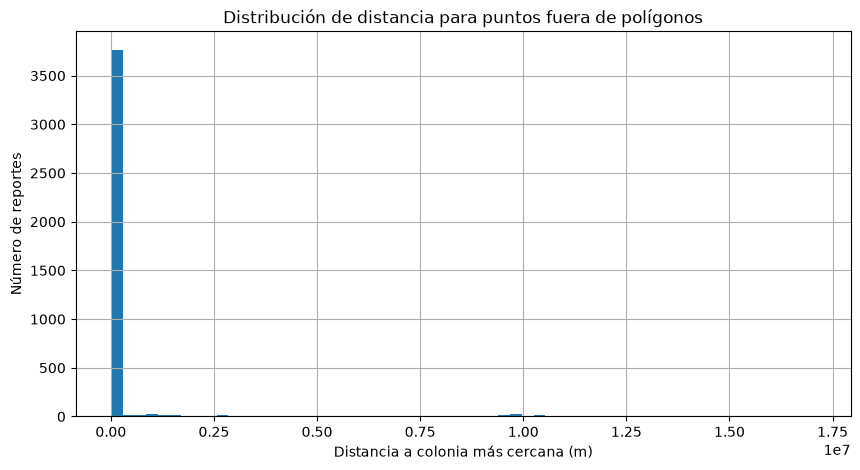

In [83]:
plt.figure(figsize=(10, 5))
df.loc[df["distance_to_colonia_m"] > 0, "distance_to_colonia_m"].hist(bins=60)
plt.xlabel("Distancia a colonia más cercana (m)")
plt.ylabel("Número de reportes")
plt.title("Distribución de distancia para puntos fuera de polígonos")
plt.show()


## 8. Comparación de colonia original vs colonia espacial


In [84]:
display(
    df["colonia_match"]
    .value_counts(dropna=False)
    .to_frame("count")
)


,count
colonia_match,
NaN,21231
False,17782
True,5


In [91]:
discrepancias = df[df["colonia_match"].eq(False)].copy()

print("Número de discrepancias:", len(discrepancias))

display(
    discrepancias[[
        "id",
        "latitude",
        "longitude",
        "colonia",
        "distance_to_colonia_m",
    ]].head(100)
)


Número de discrepancias: 17782


,id,latitude,longitude,colonia,distance_to_colonia_m
0,1,29.094161,-110.969471,Jardines de Monaco,0.000000
3,6,29.128777,-110.953926,Prados del Centenario,0.000000
4,7,29.083809,-111.042101,PRADOS DEL CENTENARIO Entre NAPOLES y REFORMA,0.000000
5,8,29.105566,-110.997993,Bachoco,0.000000
7,11,29.076253,-110.970501,Palo Verde,0.000000
9,13,29.073335,-110.973053,Loma Linda,0.000000
13,19,29.082146,-110.986191,MISION Entre REP. DE SALVADOR y REP. DE PANAMA,0.000000
14,21,29.073773,-110.947031,VILLA BONITA RESIDENCIAL,0.000000
15,28,29.123826,-110.980136,Loma Linda,0.000000
19,47,29.118391,-111.005872,ALVARO OBREGON,0.000000


In [ ]:
comparables = df["colonia_match"].notna().sum()
mismatches = df["colonia_match"].eq(False).sum()

if comparables:
    print("Porcentaje de discrepancias:", round(mismatches / comparables * 100, 2), "%")


## 9. Revisar la columna final `colonia`


In [92]:
print("Nulos en colonia final:", df["colonia"].isna().sum())
print("Valores únicos:", df["colonia"].nunique())

display(df["colonia"].value_counts(dropna=False).head(50).to_frame("count"))


Nulos en colonia final: 0
Valores únicos: 922


,count
colonia,
JESUS GARCIA Entre BENITO JUAREZ y UNO,1244
Balderrama,1069
Olivares,940
Jardines de Monaco,872
HEBERTO CASTILLO Entre ESQ. VILLA JUAREZ y XXX,789
Palo Verde,721
Country Club,620
Loma Linda,585
Modelo,551


In [93]:
context_values = [
    "cerca_asentamiento",
    "probable_carretera_o_zona_rural",
]

display(
    df[df["colonia"].isin(context_values)][[
        "id",
        "latitude",
        "longitude",
        "distance_to_colonia_m",
        "contexto_ubicacion",
        "colonia",
        "colonia_source",
    ]].head(100)
)


,id,latitude,longitude,distance_to_colonia_m,contexto_ubicacion,colonia,colonia_source
248,424,29.169169,-110.911690,1819.826394,probable_carretera_o_zona_rural,probable_carretera_o_zona_rural,contexto_ubicacion
875,1687,28.832115,-111.634678,12127.889620,probable_carretera_o_zona_rural,probable_carretera_o_zona_rural,contexto_ubicacion
1150,1989,29.130384,-110.912450,593.717427,cerca_asentamiento,cerca_asentamiento,contexto_ubicacion
1174,2013,29.183740,-110.920638,3454.086451,probable_carretera_o_zona_rural,probable_carretera_o_zona_rural,contexto_ubicacion
1309,2166,29.221949,-110.980591,4761.885642,probable_carretera_o_zona_rural,probable_carretera_o_zona_rural,contexto_ubicacion
1340,2197,29.222887,-110.972867,5068.804776,probable_carretera_o_zona_rural,probable_carretera_o_zona_rural,contexto_ubicacion
1442,2301,28.854967,-111.976534,2415.353874,probable_carretera_o_zona_rural,probable_carretera_o_zona_rural,contexto_ubicacion
1455,2314,29.067325,-111.020812,532.400131,cerca_asentamiento,cerca_asentamiento,contexto_ubicacion
1456,2315,29.067325,-111.020812,532.400131,cerca_asentamiento,cerca_asentamiento,contexto_ubicacion
1774,2644,29.036638,-111.034287,922.743952,cerca_asentamiento,cerca_asentamiento,contexto_ubicacion


### Consideración de diseño
`colonia` mezcla actualmente nombres de asentamientos con categorías como `probable_carretera_o_zona_rural`.

Una alternativa más tidy sería:
- `colonia`: únicamente nombre de colonia/asentamiento o `NA`.
- `contexto_ubicacion`: `dentro_asentamiento`, `cerca_asentamiento`, `probable_carretera_o_zona_rural`.

Conviene decidirlo después de revisar los resultados.


## 10. Revisar redundancia de columnas


Columnas candidatas a ser únicamente de auditoría:
- `colonia_original`
- `colonia_original_normalized`
- `settlement_name`
- `settlement_name_normalized`
- `colonia_match`
- `spatial_match_method`

No se recomienda eliminarlas hasta haber terminado la validación del enriquecimiento espacial.


## 11. Propuesta inicial de dataset final


In [95]:
FINAL_COLUMNS = [
    "id",
    "latitude",
    "longitude",
    "date",
    "year",
    "material",
    "description",
    "neighborhoods",
    "colonia",
    "colonia_source",
    "settlement_type",
    "distance_to_colonia_m",
    "fuera_asentamiento",
    "contexto_ubicacion",
]

missing_final_columns = [col for col in FINAL_COLUMNS if col not in df.columns]
print("Columnas faltantes:", missing_final_columns)

df_final_candidate = df[
    [col for col in FINAL_COLUMNS if col in df.columns]
].copy()

display(df_final_candidate.head())
print("Shape candidato:", df_final_candidate.shape)


Columnas faltantes: ['fuera_asentamiento']


,id,latitude,longitude,date,year,material,description,neighborhoods,colonia,colonia_source,settlement_type,distance_to_colonia_m,contexto_ubicacion
0,1,29.094161,-110.969471,2021-10-18,2021,1,"Hay un bache en la calle, y los carros se golpean y puede ocasionar un accidente, por favor quiero que lo arreglen.",[551],Jardines de Monaco,original,COLONIA,0.0,dentro_asentamiento
1,4,29.124060,-110.971318,2021-10-19,2021,1,"Buen dia! Para reportar pavimento dañado, baches y reductores de velocidas tipo boya sobre el blvd Enguerrando Tapia...",[601],Ley 57,spatial_within,COLONIA,0.0,dentro_asentamiento
2,5,29.123985,-110.971286,2021-10-19,2021,1,"Buen dia! Para reportar pavimento dañado, baches y faltante de reductores de velocidad tipo boyas amarillas sobre un...",[601],Ley 57,spatial_within,COLONIA,0.0,dentro_asentamiento
3,6,29.128777,-110.953926,2021-10-21,2021,1,toda la calle desde el blvd Morelos tiene varios baches,[49],Prados del Centenario,original,COLONIA,0.0,dentro_asentamiento
4,7,29.083809,-111.042101,2021-10-04,2021,1,C. SOLICITA BACHEO ASEGURA REPORTANTE QUE ES POR DESGASTE YA QUE SE ENCUENTRAN ALGUNOS HOYOS \r\nY EN MALAS CONDICIO...,[74],PRADOS DEL CENTENARIO Entre NAPOLES y REFORMA,original,FRACCIONAMIENTO,0.0,dentro_asentamiento


Shape candidato: (39018, 13)


## 12. Validaciones candidatas para mover al job


In [96]:
checks = {
    "id_sin_nulos": df["id"].notna().all(),
    "id_unico": df["id"].is_unique,
    "latitude_sin_nulos": df["latitude"].notna().all(),
    "longitude_sin_nulos": df["longitude"].notna().all(),
    "latitude_valida": df["latitude"].between(-90, 90).all(),
    "longitude_valida": df["longitude"].between(-180, 180).all(),
    "colonia_final_sin_nulos": df["colonia"].notna().all(),
    "distance_sin_nulos": df["distance_to_colonia_m"].notna().all(),
    "distance_no_negativa": df["distance_to_colonia_m"].ge(0).all(),
}

display(pd.Series(checks, name="cumple"))


id_sin_nulos               True
id_unico                   True
latitude_sin_nulos         True
longitude_sin_nulos        True
latitude_valida            True
longitude_valida           True
colonia_final_sin_nulos    True
distance_sin_nulos         True
distance_no_negativa       True
Name: cumple, dtype: bool

## 13. Conclusiones y decisiones

Completa esta sección después de ejecutar el notebook:

- ¿`id` puede reemplazar a `id_row`?
- ¿`date_mx` es redundante respecto a `date`?
- ¿Los umbrales espaciales actuales son razonables?
- ¿Qué porcentaje de `colonia_match=False` existe entre registros comparables?
- ¿Se deben conservar las columnas normalizadas en el dataset final o únicamente en auditoría?
- ¿`colonia` debe contener categorías de contexto o únicamente nombres de asentamiento?
- ¿Qué columnas deben quedar en el CSV final del pipeline?
